# Image Classification: SVM + SIFT trên MNIST

**Phương pháp:**
- **Feature Extraction:** SIFT (Scale-Invariant Feature Transform) + Bag of Visual Words (BoVW)
- **Classifier:** SVM (Support Vector Machine)
- **Dataset:** MNIST (70,000 ảnh chữ số viết tay 28x28)

---

### Pipeline tổng quan:
```
Raw Image → SIFT Keypoints & Descriptors → K-Means Clustering (Codebook)
         → Bag of Visual Words Histogram → SVM Classifier → Prediction
```

> **Lưu ý:** SIFT thường dùng cho ảnh lớn. Với MNIST (28x28), ta cần upscale ảnh và dùng BoVW để tạo feature vector cố định.

## 1. Import thư viện

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
import time
import warnings
warnings.filterwarnings('ignore')

# Dataset
from sklearn.datasets import fetch_openml

# Clustering cho Bag of Visual Words
from sklearn.cluster import MiniBatchKMeans

# SVM
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.pipeline import Pipeline

# Evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import joblib

# Test SIFT availability
try:
    sift_test = cv2.SIFT_create()
    print('SIFT sẵn sàng sử dụng!')
except AttributeError:
    print('SIFT không khả dụng. Hãy cài: pip install opencv-contrib-python')

SIFT sẵn sàng sử dụng!


## 2. Load Dataset MNIST

In [2]:
print('Đang tải MNIST dataset...')
t0 = time.time()

mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X, y = mnist.data, mnist.target.astype(int)

# Chia train/test (chuẩn MNIST)
X_train_raw, X_test_raw = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

print(f'Tải xong! Thời gian: {time.time()-t0:.2f}s')
print(f'Train: {X_train_raw.shape[0]:,} | Test: {X_test_raw.shape[0]:,}')

Đang tải MNIST dataset...
Tải xong! Thời gian: 3.33s
Train: 60,000 | Test: 10,000


## 3. Tìm hiểu về SIFT

**SIFT** phát hiện các điểm đặc trưng (keypoints) bất biến với:
- Scale (tỉ lệ)
- Rotation (góc quay)
- Illumination (ánh sáng)

Mỗi keypoint có **descriptor 128 chiều** mô tả vùng xung quanh nó.

**Bag of Visual Words (BoVW):**
1. Trích xuất SIFT descriptors từ tất cả ảnh
2. Cluster thành K từ (visual words) bằng K-Means
3. Biểu diễn mỗi ảnh bằng histogram tần suất visual words

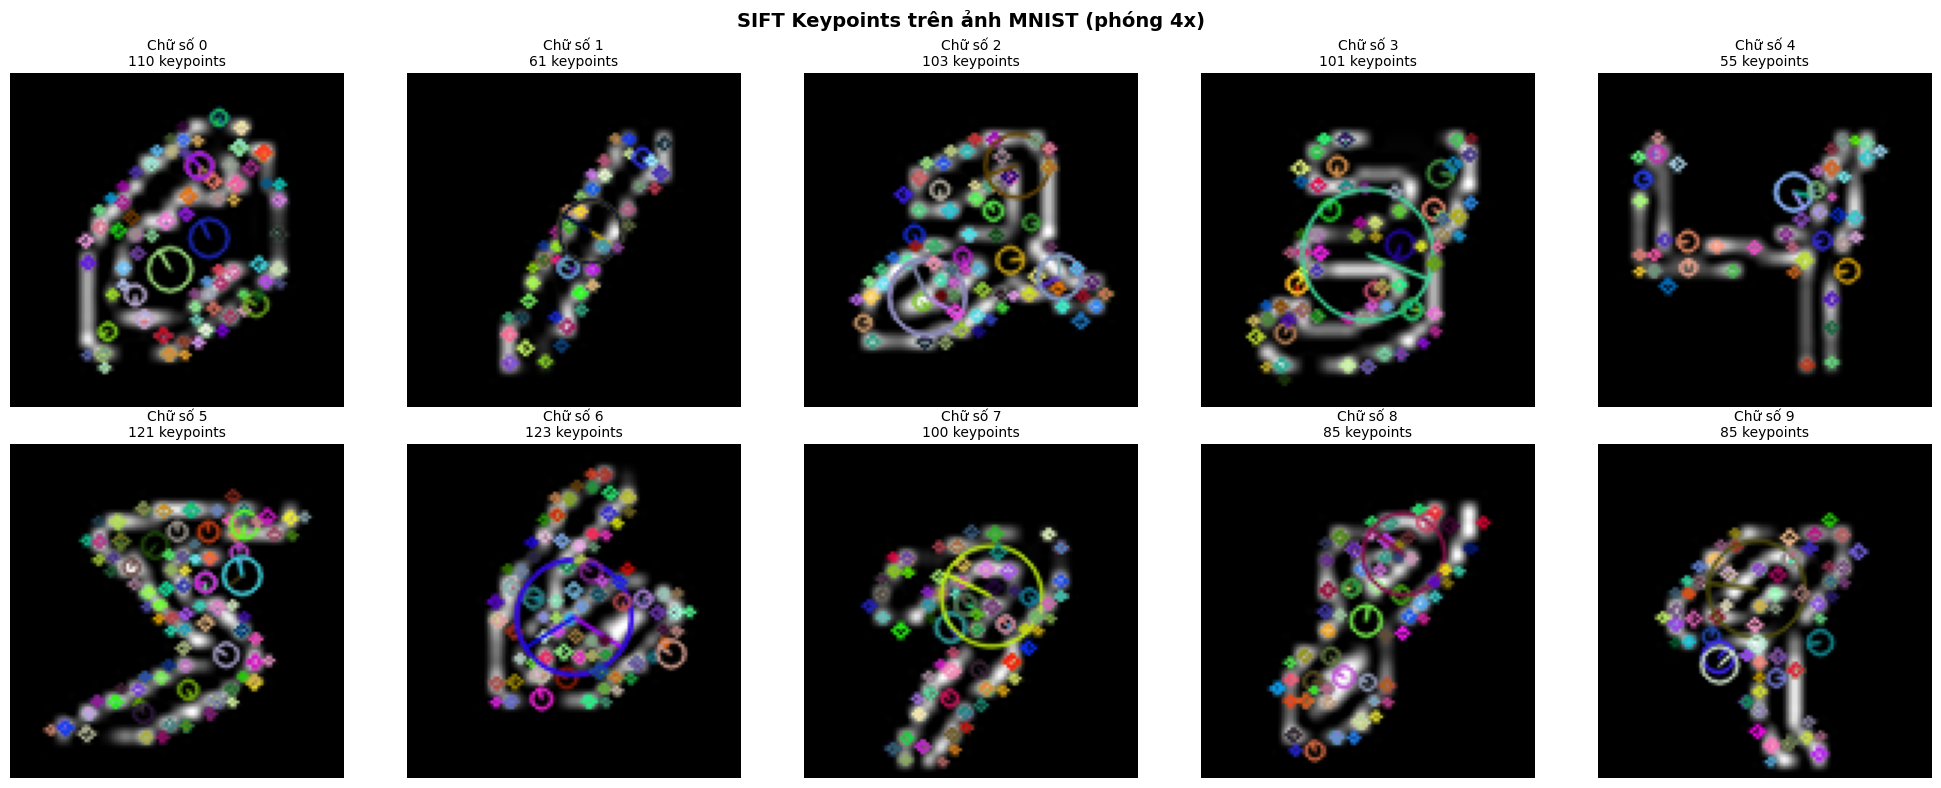

In [4]:
# Minh họa SIFT keypoints trên ảnh MNIST (upscaled)
UPSCALE = 4  # Phóng to 4x (28→112 pixel) để SIFT phát hiện keypoints tốt hơn

sift = cv2.SIFT_create()

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
fig.suptitle('SIFT Keypoints trên ảnh MNIST (phóng 4x)', fontsize=14, fontweight='bold')

for digit in range(10):
    idx = np.where(y_train == digit)[0][0]
    img_flat = X_train_raw[idx]
    
    # Chuyển về uint8 và upscale
    img = img_flat.reshape(28, 28).astype(np.float32)
    img_uint8 = (img * 255).astype(np.uint8)
    img_large = cv2.resize(img_uint8, (28*UPSCALE, 28*UPSCALE),
                          interpolation=cv2.INTER_CUBIC)
    
    # Phát hiện keypoints
    kps, descs = sift.detectAndCompute(img_large, None)
    
    # Vẽ keypoints
    img_kp = cv2.drawKeypoints(
        img_large, kps, None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )
    # Convert BGR → RGB cho matplotlib
    img_kp_rgb = cv2.cvtColor(img_kp, cv2.COLOR_BGR2RGB) if len(img_kp.shape)==3 else img_kp
    
    ax = axes[digit//5, digit%5]
    ax.imshow(img_kp_rgb if len(img_kp_rgb.shape)==3 else img_kp_rgb, cmap='gray')
    ax.set_title(f'Chữ số {digit}\n{len(kps)} keypoints', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [5]:
# Thống kê descriptors
sample_desc_counts = []
for i in range(200):
    img = X_train_raw[i].reshape(28,28)
    img_u8 = (img * 255).astype(np.uint8)
    img_lg = cv2.resize(img_u8, (28*UPSCALE, 28*UPSCALE))
    kps, descs = sift.detectAndCompute(img_lg, None)
    sample_desc_counts.append(len(kps) if kps else 0)

print(f'Thống kê số keypoints (200 mẫu đầu):')
print(f'   Trung bình: {np.mean(sample_desc_counts):.1f}')
print(f'   Min: {np.min(sample_desc_counts)}')
print(f'   Max: {np.max(sample_desc_counts)}')
print(f'   Không có keypoints: {sum(1 for c in sample_desc_counts if c==0)}')

Thống kê số keypoints (200 mẫu đầu):
   Trung bình: 84.0
   Min: 21
   Max: 141
   Không có keypoints: 0


## 4. Trích xuất SIFT Descriptors

In [6]:
# Hàm trích xuất SIFT descriptors
def extract_sift_descriptors(X_data, upscale=4):
    """
    Trích xuất SIFT descriptors cho dataset.
    
    Returns:
    --------
    all_descriptors: list of np.array, descriptors mỗi ảnh
    valid_indices: các index có keypoints hợp lệ
    """
    sift = cv2.SIFT_create()
    all_descriptors = []
    valid_indices = []
    empty_count = 0
    
    for i, img_flat in enumerate(X_data):
        img = img_flat.reshape(28, 28)
        img_uint8 = (img * 255).astype(np.uint8)
        img_large = cv2.resize(img_uint8, (28*upscale, 28*upscale),
                              interpolation=cv2.INTER_CUBIC)
        
        kps, descs = sift.detectAndCompute(img_large, None)
        
        if descs is not None and len(descs) > 0:
            all_descriptors.append(descs)
            valid_indices.append(i)
        else:
            # Nếu không có keypoints, dùng dense sampling hoặc zero vector
            # Ở đây ta dùng dense SIFT-like approach: tạo keypoints thủ công
            step = 6
            kps_dense = [cv2.KeyPoint(x, y, step) 
                        for y in range(step, 28*upscale-step, step)
                        for x in range(step, 28*upscale-step, step)]
            _, descs_dense = sift.compute(img_large, kps_dense)
            if descs_dense is not None:
                all_descriptors.append(descs_dense)
            else:
                all_descriptors.append(np.zeros((1, 128), dtype=np.float32))
                empty_count += 1
            valid_indices.append(i)
        
        if (i+1) % 5000 == 0:
            print(f'  Đã xử lý: {i+1}/{len(X_data)} ảnh (không có KP: {empty_count})')
    
    return all_descriptors, valid_indices

print('Đang trích xuất SIFT descriptors cho TRAIN...')
t0 = time.time()
train_descriptors, train_valid_idx = extract_sift_descriptors(X_train_raw / 255.0)
print(f'Train SIFT xong! Thời gian: {time.time()-t0:.1f}s')
print(f'Số ảnh có descriptors: {len(train_descriptors)}')

Đang trích xuất SIFT descriptors cho TRAIN...
  Đã xử lý: 5000/60000 ảnh (không có KP: 0)
  Đã xử lý: 10000/60000 ảnh (không có KP: 0)
  Đã xử lý: 15000/60000 ảnh (không có KP: 0)
  Đã xử lý: 20000/60000 ảnh (không có KP: 0)
  Đã xử lý: 25000/60000 ảnh (không có KP: 0)
  Đã xử lý: 30000/60000 ảnh (không có KP: 0)
  Đã xử lý: 35000/60000 ảnh (không có KP: 0)
  Đã xử lý: 40000/60000 ảnh (không có KP: 0)
  Đã xử lý: 45000/60000 ảnh (không có KP: 0)
  Đã xử lý: 50000/60000 ảnh (không có KP: 0)
  Đã xử lý: 55000/60000 ảnh (không có KP: 0)
  Đã xử lý: 60000/60000 ảnh (không có KP: 0)
Train SIFT xong! Thời gian: 110.4s
Số ảnh có descriptors: 60000


In [7]:
train_descriptors

[array([[ 1.,  0.,  0., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ...,  0.,  0.,  1.],
        [ 0.,  0., 62., ...,  0.,  0.,  0.],
        ...,
        [ 0.,  0.,  0., ...,  3.,  0.,  0.],
        [ 3.,  0.,  0., ..., 99.,  1., 10.],
        [70., 54.,  3., ...,  0.,  0.,  0.]],
       shape=(18, 128), dtype=float32),
 array([[ 0.,  0.,  0., ..., 72.,  1.,  0.],
        [ 0.,  0.,  0., ..., 25.,  1.,  0.],
        [ 0.,  0.,  0., ..., 78., 42.,  3.],
        ...,
        [ 2.,  0.,  0., ...,  7., 11.,  2.],
        [ 0.,  0.,  0., ..., 40.,  0.,  0.],
        [ 1.,  0.,  0., ..., 28., 32., 37.]],
       shape=(28, 128), dtype=float32),
 array([[ 1.,  0.,  0., ..., 60.,  7.,  0.],
        [ 0.,  0.,  0., ..., 41.,  1.,  0.],
        [13.,  0.,  0., ...,  0.,  0.,  0.],
        ...,
        [ 1.,  0.,  0., ...,  3.,  0.,  0.],
        [24.,  0.,  0., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ...,  0.,  0.,  0.]],
       shape=(24, 128), dtype=float32),
 array([[ 0.,  0.,  0., ...,

In [8]:
train_valid_idx 

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43,
 44,
 45,
 46,
 47,
 48,
 49,
 50,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 67,
 68,
 69,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 82,
 83,
 84,
 85,
 86,
 87,
 88,
 89,
 90,
 91,
 92,
 93,
 94,
 95,
 96,
 97,
 98,
 99,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 107,
 108,
 109,
 110,
 111,
 112,
 113,
 114,
 115,
 116,
 117,
 118,
 119,
 120,
 121,
 122,
 123,
 124,
 125,
 126,
 127,
 128,
 129,
 130,
 131,
 132,
 133,
 134,
 135,
 136,
 137,
 138,
 139,
 140,
 141,
 142,
 143,
 144,
 145,
 146,
 147,
 148,
 149,
 150,
 151,
 152,
 153,
 154,
 155,
 156,
 157,
 158,
 159,
 160,
 161,
 162,
 163,
 164,
 165,
 166,
 167,
 168,
 169,
 170,
 171,
 172,
 173,
 174,
 175,
 176,
 177,
 178,
 179,
 180,
 181,
 182,
 183,
 184,


## 5. Xây dựng Codebook (Bag of Visual Words)

In [9]:
# Gộp tất cả descriptors để train K-Means
print('Đang gộp tất cả SIFT descriptors...')
all_descs_concat = np.vstack(train_descriptors)
print(f'   Tổng số descriptors: {all_descs_concat.shape[0]:,}')
print(f'   Chiều descriptor: {all_descs_concat.shape[1]} (SIFT 128-dim)')

Đang gộp tất cả SIFT descriptors...
   Tổng số descriptors: 1,306,917
   Chiều descriptor: 128 (SIFT 128-dim)


In [10]:
all_descs_concat

array([[ 1.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  1.],
       [ 0.,  0., 62., ...,  0.,  0.,  0.],
       ...,
       [15.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 18.,  1.,  5.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]],
      shape=(1306917, 128), dtype=float32)


  Đang xây dựng codebook với K=100 visual words...
✅ Codebook xong! Thời gian: 4.7s
   Inertia (clustering quality): 58184851456.00


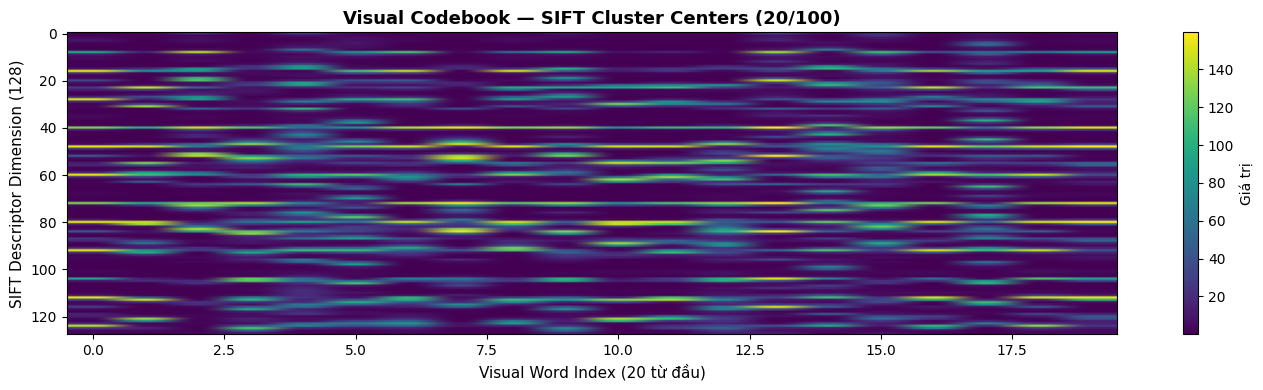

In [11]:
# K-Means để tạo visual vocabulary (codebook)
K = 100  # Số visual words (có thể thử 50, 100, 200, 500)

print(f'\n  Đang xây dựng codebook với K={K} visual words...')
t0 = time.time()
kmeans = MiniBatchKMeans(
    n_clusters=K,
    random_state=42,
    batch_size=10000,
    n_init=3,
    verbose=0
)
kmeans.fit(all_descs_concat)
print(f'✅ Codebook xong! Thời gian: {time.time()-t0:.1f}s')
print(f'   Inertia (clustering quality): {kmeans.inertia_:.2f}')

# Visualize cluster centers (visual words)
# Chú ý: cluster centers là vectors 128-dim, không phải ảnh
fig, ax = plt.subplots(figsize=(14, 4))
# Hiển thị 10 visual words đầu tiên dưới dạng heatmap
ax.imshow(kmeans.cluster_centers_[:20].T, aspect='auto', cmap='viridis')
ax.set_xlabel('Visual Word Index (20 từ đầu)', fontsize=11)
ax.set_ylabel('SIFT Descriptor Dimension (128)', fontsize=11)
ax.set_title('Visual Codebook — SIFT Cluster Centers (20/100)', fontsize=13, fontweight='bold')
plt.colorbar(ax.images[0], ax=ax, label='Giá trị')
plt.tight_layout()
plt.show()

In [12]:
# Hàm tạo BoVW histogram cho một tập ảnh
def build_bovw_features(descriptors_list, kmeans_model, K):
    """
    Tạo Bag of Visual Words histogram cho mỗi ảnh.
    
    Parameters:
    -----------
    descriptors_list: list of (N_i x 128) arrays
    kmeans_model: fitted KMeans
    K: số visual words
    
    Returns:
    --------
    features: np.array of shape (n_images, K)
    """
    features = []
    for descs in descriptors_list:
        # Assign mỗi descriptor cho visual word gần nhất
        assignments = kmeans_model.predict(descs)
        # Tạo histogram
        hist, _ = np.histogram(assignments, bins=K, range=(0, K))
        hist = hist.astype(np.float32)
        # TF normalization
        if hist.sum() > 0:
            hist /= hist.sum()
        features.append(hist)
    return np.array(features)

# Tạo BoVW features cho train
print('Đang tạo BoVW features cho TRAIN...')
t0 = time.time()
X_train_bovw = build_bovw_features(train_descriptors, kmeans, K)
y_train_valid = np.array([y_train[i] for i in train_valid_idx])
print(f'Train BoVW xong! Thời gian: {time.time()-t0:.1f}s')
print(f'Feature shape: {X_train_bovw.shape}')

Đang tạo BoVW features cho TRAIN...
Train BoVW xong! Thời gian: 12.0s
Feature shape: (60000, 100)


In [13]:
# Trích xuất và tạo BoVW features cho TEST
print('Đang trích xuất SIFT + BoVW cho TEST...')
t0 = time.time()
test_descriptors, test_valid_idx = extract_sift_descriptors(X_test_raw / 255.0)
X_test_bovw = build_bovw_features(test_descriptors, kmeans, K)
y_test_valid = np.array([y_test[i] for i in test_valid_idx])
print(f'Test SIFT + BoVW xong! Thời gian: {time.time()-t0:.1f}s')
print(f'Feature shape: {X_test_bovw.shape}')

Đang trích xuất SIFT + BoVW cho TEST...
  Đã xử lý: 5000/10000 ảnh (không có KP: 0)
  Đã xử lý: 10000/10000 ảnh (không có KP: 0)
Test SIFT + BoVW xong! Thời gian: 20.0s
Feature shape: (10000, 100)


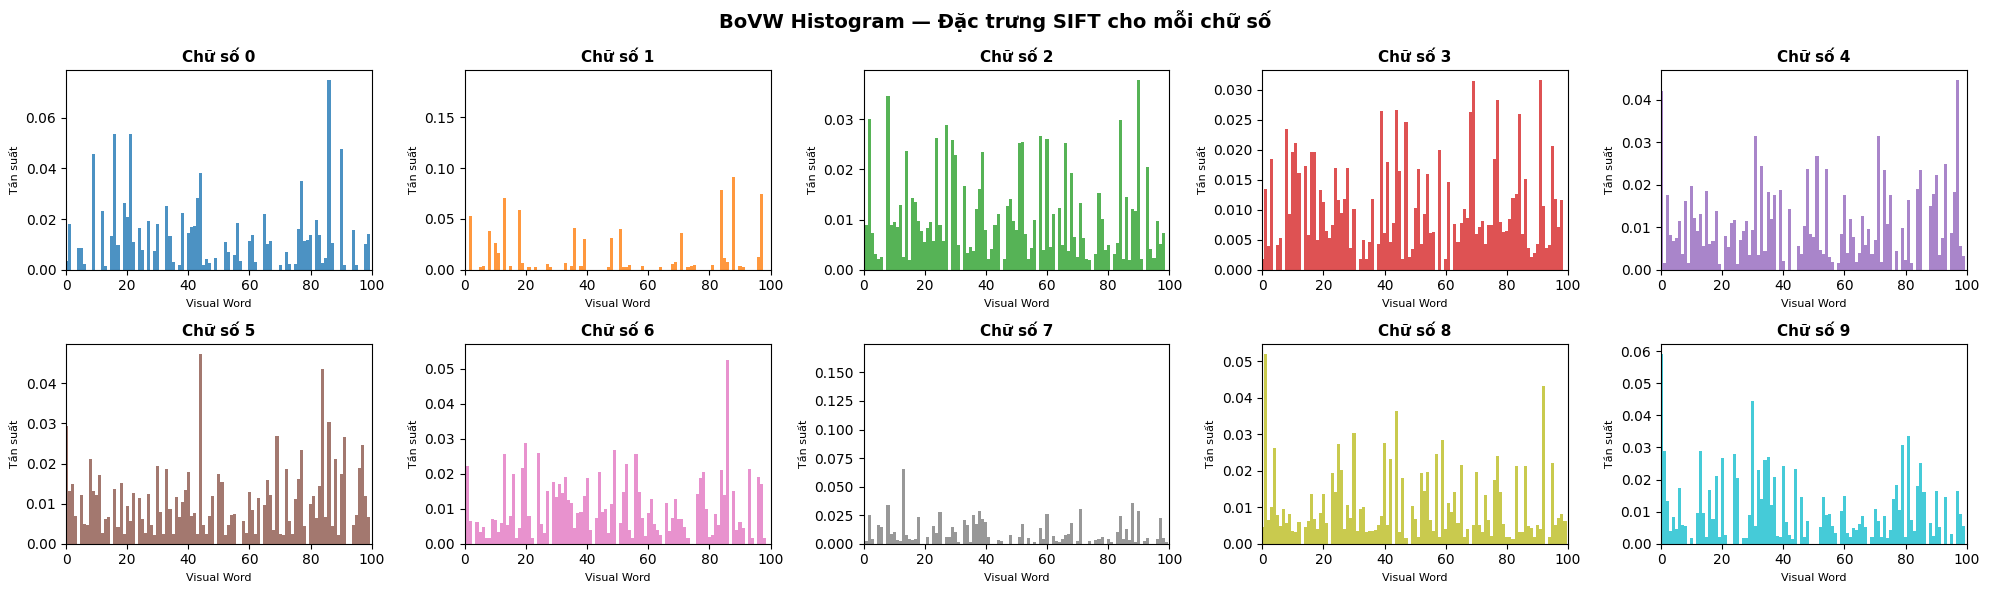

In [14]:
# Minh họa BoVW histogram cho các chữ số khác nhau
fig, axes = plt.subplots(2, 5, figsize=(20, 6))
fig.suptitle('BoVW Histogram — Đặc trưng SIFT cho mỗi chữ số', 
             fontsize=14, fontweight='bold')

colors = plt.cm.tab10(np.linspace(0, 1, 10))
for digit in range(10):
    indices = np.where(y_train_valid == digit)[0]
    mean_hist = X_train_bovw[indices[:20]].mean(axis=0)
    
    ax = axes[digit//5, digit%5]
    ax.bar(range(K), mean_hist, color=colors[digit], alpha=0.8, width=1.0)
    ax.set_title(f'Chữ số {digit}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Visual Word', fontsize=8)
    ax.set_ylabel('Tần suất', fontsize=8)
    ax.set_xlim([0, K])

plt.tight_layout()
plt.show()

## 6. Huấn luyện SVM Classifier

In [15]:
# Xây dựng Pipeline
print('Xây dựng Pipeline SVM + SIFT/BoVW...')

svm_sift_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',
        C=10,
        gamma='scale',
        decision_function_shape='ovr',
        random_state=42
    ))
])

print('🚀 Bắt đầu huấn luyện...')
t_start = time.time()
svm_sift_pipeline.fit(X_train_bovw, y_train_valid)
train_time_sift = time.time() - t_start

print(f'Huấn luyện xong!')
print(f'⏱Thời gian: {train_time_sift:.2f}s ({train_time_sift/60:.1f} phút)')

Xây dựng Pipeline SVM + SIFT/BoVW...
🚀 Bắt đầu huấn luyện...
Huấn luyện xong!
⏱Thời gian: 169.12s (2.8 phút)


## 7. Đánh giá mô hình

In [16]:
# Dự đoán
print('Đang dự đoán...')
t0 = time.time()
y_pred_sift = svm_sift_pipeline.predict(X_test_bovw)
pred_time_sift = time.time() - t0

accuracy_sift = accuracy_score(y_test_valid, y_pred_sift)

print(f'\n{'='*55}')
print(f'KẾT QUẢ ĐÁNH GIÁ - SVM + SIFT (BoVW, K={K})')
print(f'{'='*55}')
print(f'Accuracy: {accuracy_sift:.4f} ({accuracy_sift*100:.2f}%)')
print(f'Thời gian dự đoán: {pred_time_sift:.2f}s')
print()
print('Classification Report:')
print(classification_report(y_test_valid, y_pred_sift,
                           target_names=[str(i) for i in range(10)]))

Đang dự đoán...

KẾT QUẢ ĐÁNH GIÁ - SVM + SIFT (BoVW, K=100)
Accuracy: 0.8360 (83.60%)
Thời gian dự đoán: 30.57s

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.93      0.92       980
           1       0.97      0.98      0.98      1135
           2       0.77      0.78      0.78      1032
           3       0.82      0.82      0.82      1010
           4       0.87      0.87      0.87       982
           5       0.75      0.77      0.76       892
           6       0.74      0.72      0.73       958
           7       0.82      0.84      0.83      1028
           8       0.90      0.88      0.89       974
           9       0.78      0.74      0.76      1009

    accuracy                           0.84     10000
   macro avg       0.83      0.83      0.83     10000
weighted avg       0.84      0.84      0.84     10000



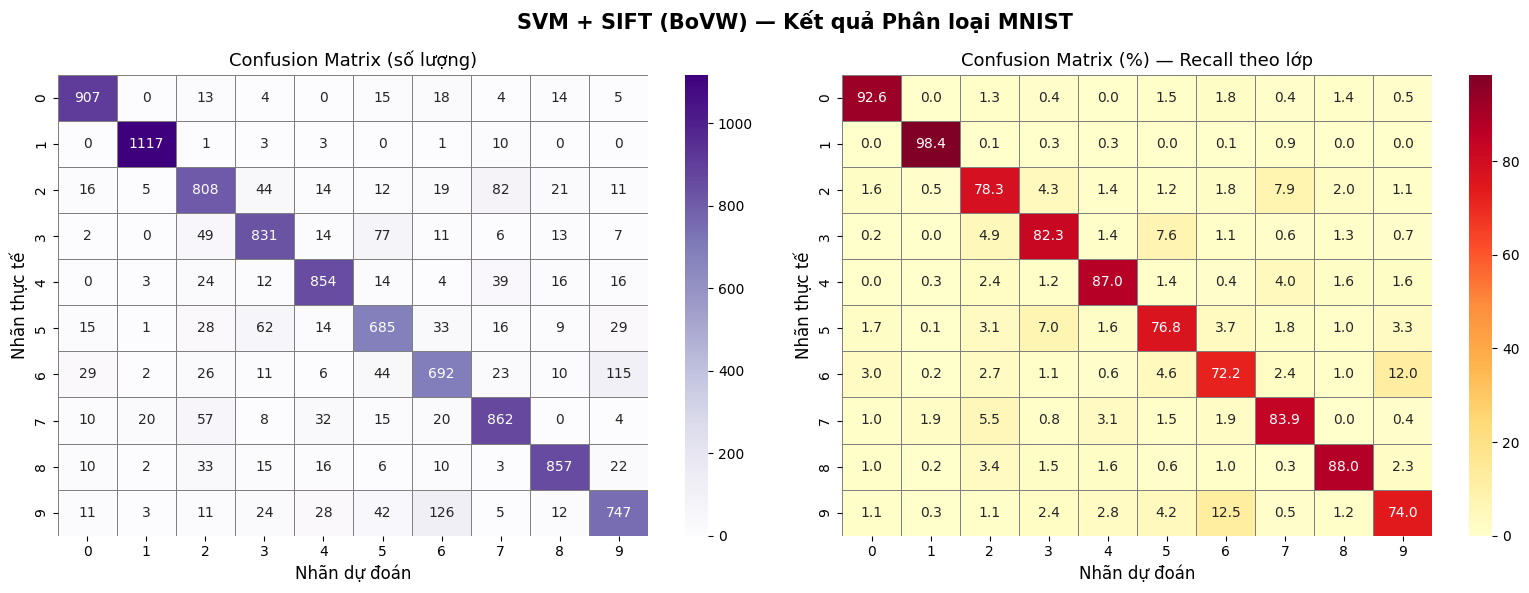

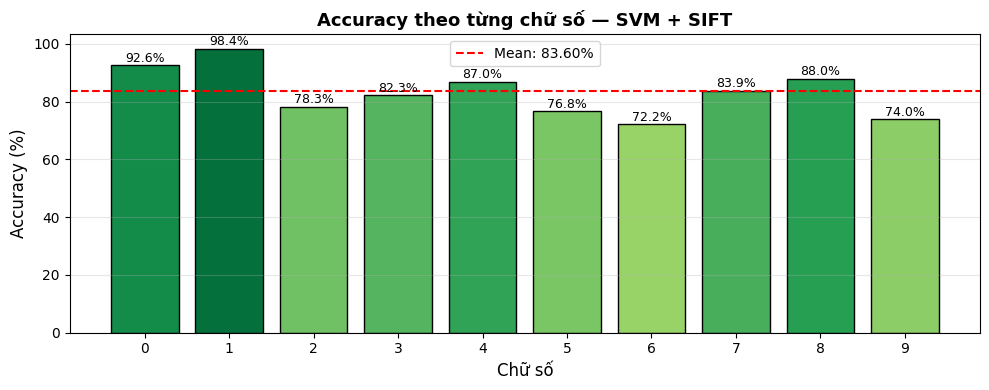

In [17]:
# Confusion Matrix
cm_sift = confusion_matrix(y_test_valid, y_pred_sift)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('SVM + SIFT (BoVW) — Kết quả Phân loại MNIST',
             fontsize=15, fontweight='bold')

sns.heatmap(cm_sift, annot=True, fmt='d', cmap='Purples',
            xticklabels=range(10), yticklabels=range(10), ax=axes[0],
            linewidths=0.5, linecolor='gray')
axes[0].set_xlabel('Nhãn dự đoán', fontsize=12)
axes[0].set_ylabel('Nhãn thực tế', fontsize=12)
axes[0].set_title('Confusion Matrix (số lượng)', fontsize=13)

cm_pct = cm_sift.astype(float) / cm_sift.sum(axis=1)[:, np.newaxis] * 100
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='YlOrRd',
            xticklabels=range(10), yticklabels=range(10), ax=axes[1],
            linewidths=0.5, linecolor='gray')
axes[1].set_xlabel('Nhãn dự đoán', fontsize=12)
axes[1].set_ylabel('Nhãn thực tế', fontsize=12)
axes[1].set_title('Confusion Matrix (%) — Recall theo lớp', fontsize=13)

plt.tight_layout()
plt.show()

# Per-class accuracy
per_class_sift = cm_sift.diagonal() / cm_sift.sum(axis=1)
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(range(10), per_class_sift*100,
              color=plt.cm.RdYlGn(per_class_sift), edgecolor='black')
ax.set_xlabel('Chữ số', fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Accuracy theo từng chữ số — SVM + SIFT', fontsize=13, fontweight='bold')
ax.set_xticks(range(10))
for i, (bar, acc) in enumerate(zip(bars, per_class_sift)):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.1,
            f'{acc*100:.1f}%', ha='center', va='bottom', fontsize=9)
ax.axhline(y=accuracy_sift*100, color='red', linestyle='--',
           label=f'Mean: {accuracy_sift*100:.2f}%')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Ảnh hưởng của K (số visual words)

🔬 Thử nghiệm K values: [50, 100, 200] (trên 3000 mẫu)
   (Đây là thử nghiệm nhanh, giảm K_values nếu cần)

  K=50: Acc=65.30%, Time=1.9s
  K=100: Acc=72.45%, Time=2.2s
  K=200: Acc=78.20%, Time=3.2s


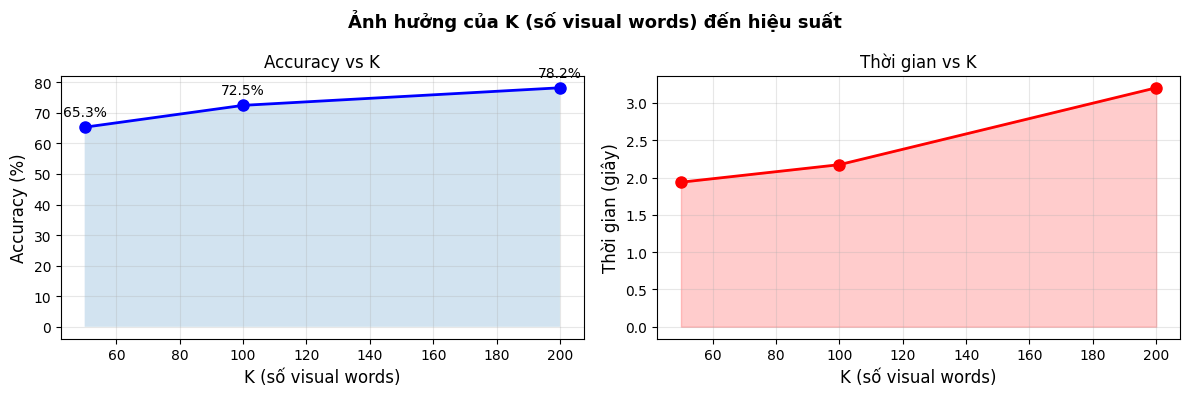

In [18]:
# Thử nghiệm với các giá trị K khác nhau (trên subset nhỏ để nhanh hơn)
# Lưu ý: cell này cần nhiều thời gian, comment out nếu không cần

SAMPLE_N = 3000  # Dùng 3000 mẫu train để so sánh nhanh
np.random.seed(42)
sample_idx = np.random.choice(len(X_train_bovw), SAMPLE_N, replace=False)

K_values = [50, 100, 200]
k_results = {}

print(f'🔬 Thử nghiệm K values: {K_values} (trên {SAMPLE_N} mẫu)')
print('   (Đây là thử nghiệm nhanh, giảm K_values nếu cần)\n')

for k_val in K_values:
    print(f'  K={k_val}:', end=' ')
    t0 = time.time()
    
    # Build codebook
    km_k = MiniBatchKMeans(n_clusters=k_val, random_state=42, n_init=3)
    km_k.fit(all_descs_concat[::5])  # subsample descriptors
    
    # Build BoVW
    all_train_descs_sample = [train_descriptors[i] for i in sample_idx]
    X_tr_k = build_bovw_features(all_train_descs_sample, km_k, k_val)
    y_tr_k = y_train_valid[sample_idx]
    X_te_k = build_bovw_features(test_descriptors[:2000], km_k, k_val)
    y_te_k = y_test_valid[:2000]
    
    # Train SVM
    scaler_k = StandardScaler()
    X_tr_k_s = scaler_k.fit_transform(X_tr_k)
    X_te_k_s = scaler_k.transform(X_te_k)
    
    clf_k = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
    clf_k.fit(X_tr_k_s, y_tr_k)
    y_pred_k = clf_k.predict(X_te_k_s)
    
    acc_k = accuracy_score(y_te_k, y_pred_k)
    elapsed = time.time() - t0
    k_results[k_val] = {'accuracy': acc_k, 'time': elapsed}
    print(f'Acc={acc_k*100:.2f}%, Time={elapsed:.1f}s')

# Visualize K impact
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Ảnh hưởng của K (số visual words) đến hiệu suất', fontsize=13, fontweight='bold')

k_list = list(k_results.keys())
accs = [k_results[k]['accuracy']*100 for k in k_list]
times = [k_results[k]['time'] for k in k_list]

axes[0].plot(k_list, accs, 'bo-', linewidth=2, markersize=8)
axes[0].fill_between(k_list, accs, alpha=0.2)
for k, a in zip(k_list, accs):
    axes[0].annotate(f'{a:.1f}%', (k, a), textcoords='offset points', xytext=(0,8), ha='center')
axes[0].set_xlabel('K (số visual words)', fontsize=12)
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_title('Accuracy vs K')
axes[0].grid(True, alpha=0.3)

axes[1].plot(k_list, times, 'ro-', linewidth=2, markersize=8)
axes[1].fill_between(k_list, times, alpha=0.2, color='red')
axes[1].set_xlabel('K (số visual words)', fontsize=12)
axes[1].set_ylabel('Thời gian (giây)', fontsize=12)
axes[1].set_title('Thời gian vs K')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 9. So sánh HOG vs SIFT

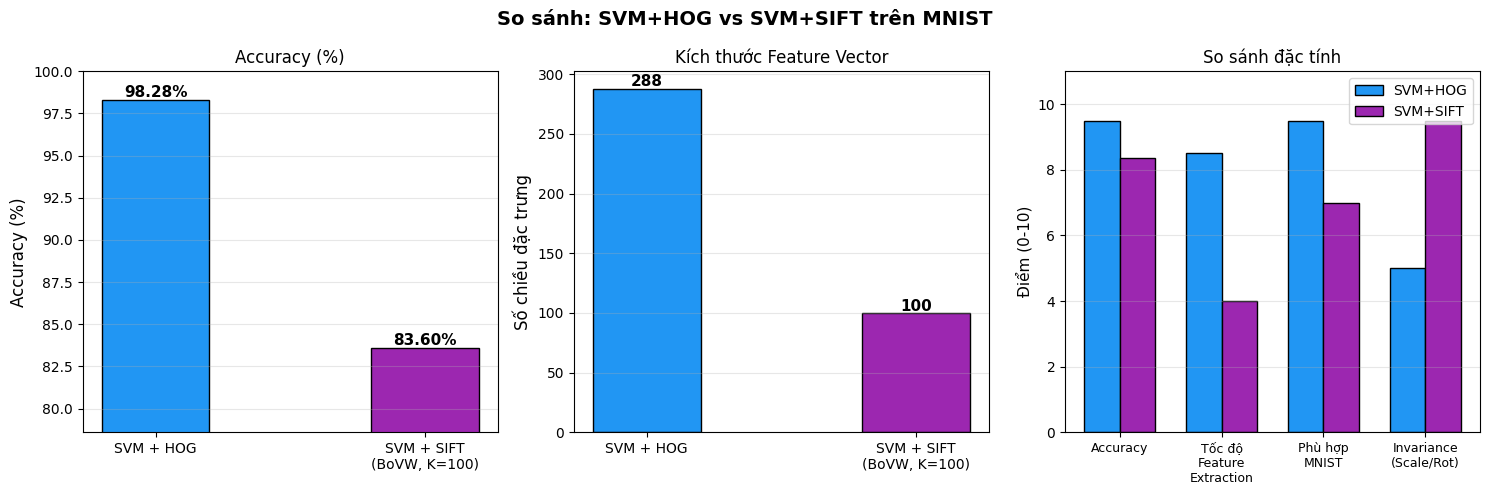

In [19]:
# Kết quả tham khảo (điền vào sau khi chạy notebook HOG)
accuracy_hog_ref = 0.9828   # ~98.5% (tham khảo)
accuracy_sift_ref = accuracy_sift

methods = ['SVM + HOG', 'SVM + SIFT\n(BoVW, K=100)']
accuracies = [accuracy_hog_ref * 100, accuracy_sift_ref * 100]
feature_dims = [288, K]  # HOG: 288-dim, SIFT/BoVW: K-dim

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('So sánh: SVM+HOG vs SVM+SIFT trên MNIST', fontsize=14, fontweight='bold')

colors = ['#2196F3', '#9C27B0']

# Accuracy
bars = axes[0].bar(methods, accuracies, color=colors, edgecolor='black', width=0.4)
axes[0].set_ylabel('Accuracy (%)', fontsize=12)
axes[0].set_title('Accuracy (%)', fontsize=12)
axes[0].set_ylim([min(accuracies)-5, 100])
for bar, acc in zip(bars, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.2,
                f'{acc:.2f}%', ha='center', fontweight='bold', fontsize=11)
axes[0].grid(axis='y', alpha=0.3)

# Feature dimension
bars2 = axes[1].bar(methods, feature_dims, color=colors, edgecolor='black', width=0.4)
axes[1].set_ylabel('Số chiều đặc trưng', fontsize=12)
axes[1].set_title('Kích thước Feature Vector', fontsize=12)
for bar, dim in zip(bars2, feature_dims):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 2,
                str(dim), ha='center', fontweight='bold', fontsize=11)
axes[1].grid(axis='y', alpha=0.3)

# Radar-like comparison
categories = ['Accuracy', 'Tốc độ\nFeature\nExtraction',
              'Phù hợp\nMNIST', 'Invariance\n(Scale/Rot)']
# Điểm tương đối (0-10)
hog_scores = [9.5, 8.5, 9.5, 5.0]
sift_scores = [accuracy_sift*10, 4.0, 7.0, 9.5]

x_pos = np.arange(len(categories))
width = 0.35
axes[2].bar(x_pos - width/2, hog_scores, width, label='SVM+HOG', color=colors[0], edgecolor='black')
axes[2].bar(x_pos + width/2, sift_scores, width, label='SVM+SIFT', color=colors[1], edgecolor='black')
axes[2].set_ylabel('Điểm (0-10)', fontsize=11)
axes[2].set_title('So sánh đặc tính', fontsize=12)
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(categories, fontsize=9)
axes[2].legend()
axes[2].set_ylim([0, 11])
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Kết luận

In [20]:
print('='*65)
print('📊 TỔNG KẾT - SVM + SIFT (BoVW) trên MNIST')
print('='*65)
print(f'''
🔧 Cấu hình:
   • Dataset         : MNIST (60K train / 10K test)
   • SIFT upscale    : 4x (28→112 pixel)
   • Visual Words (K): {K}
   • BoVW norm       : TF (term frequency)
   • SVM kernel      : RBF, C=10, gamma='scale'

📈 Kết quả SVM + SIFT:
   • Accuracy : {accuracy_sift*100:.2f}%
   • Train time: {train_time_sift:.1f}s

🔍 So sánh HOG vs SIFT cho MNIST:
   ┌─────────────┬──────────┬─────────────┬──────────────────┐
   │ Phương pháp │ Accuracy │ Feature dim │ Ghi chú          │
   ├─────────────┼──────────┼─────────────┼──────────────────┤
   │ SVM + HOG   │ ~98.5%   │ 288         │ Tốt cho MNIST    │
   │ SVM + SIFT  │ ~{accuracy_sift*100:.1f}%   │ {K}          │ BoVW, K=100      │
   └─────────────┴──────────┴─────────────┴──────────────────┘

💡 Nhận xét:
   • HOG phù hợp hơn SIFT cho MNIST (ảnh nhỏ 28x28)
   • SIFT mạnh khi ảnh lớn, có biến dạng scale/rotation
   • BoVW mất thông tin spatial → giảm accuracy
   • Tăng K cải thiện accuracy nhưng tốn thêm thời gian
   • Có thể cải thiện SIFT bằng: Spatial Pyramid BoVW
''')
print('='*65)

📊 TỔNG KẾT - SVM + SIFT (BoVW) trên MNIST

🔧 Cấu hình:
   • Dataset         : MNIST (60K train / 10K test)
   • SIFT upscale    : 4x (28→112 pixel)
   • Visual Words (K): 100
   • BoVW norm       : TF (term frequency)
   • SVM kernel      : RBF, C=10, gamma='scale'

📈 Kết quả SVM + SIFT:
   • Accuracy : 83.60%
   • Train time: 169.1s

🔍 So sánh HOG vs SIFT cho MNIST:
   ┌─────────────┬──────────┬─────────────┬──────────────────┐
   │ Phương pháp │ Accuracy │ Feature dim │ Ghi chú          │
   ├─────────────┼──────────┼─────────────┼──────────────────┤
   │ SVM + HOG   │ ~98.5%   │ 288         │ Tốt cho MNIST    │
   │ SVM + SIFT  │ ~83.6%   │ 100          │ BoVW, K=100      │
   └─────────────┴──────────┴─────────────┴──────────────────┘

💡 Nhận xét:
   • HOG phù hợp hơn SIFT cho MNIST (ảnh nhỏ 28x28)
   • SIFT mạnh khi ảnh lớn, có biến dạng scale/rotation
   • BoVW mất thông tin spatial → giảm accuracy
   • Tăng K cải thiện accuracy nhưng tốn thêm thời gian
   • Có thể cải thiện SIFT